Model for Credit risk analysis for providing bank loans

# Import Liberaries

In [13]:
import pandas as pd

pd.set_option('display.max_columns', None)

pd.set_option('display.max_rows', None)

import numpy as np

import matplotlib.pyplot as plt

import matplotlib.gridspec as gridspec

import seaborn as sns

import plotly.express as px

import plotly.graph_objects as go

from plotly.subplots import make_subplots

import plotly.tools as tls
import plotly.offline as py      


import warnings

warnings.filterwarnings("ignore")

# Read Data

In [15]:
df = pd.read_csv('data/loan.csv/loan.csv')

In [16]:
df.head(3)

,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,emp_title,emp_length,home_ownership,annual_inc,verification_status,issue_d,loan_status,pymnt_plan,url,desc,purpose,title,zip_code,addr_state,dti,delinq_2yrs,earliest_cr_line,inq_last_6mths,mths_since_last_delinq,mths_since_last_record,open_acc,pub_rec,revol_bal,revol_util,total_acc,initial_list_status,out_prncp,out_prncp_inv,total_pymnt,total_pymnt_inv,total_rec_prncp,total_rec_int,total_rec_late_fee,recoveries,collection_recovery_fee,last_pymnt_d,last_pymnt_amnt,next_pymnt_d,last_credit_pull_d,collections_12_mths_ex_med,mths_since_last_major_derog,policy_code,application_type,annual_inc_joint,dti_joint,verification_status_joint,acc_now_delinq,tot_coll_amt,tot_cur_bal,open_acc_6m,open_il_6m,open_il_12m,open_il_24m,mths_since_rcnt_il,total_bal_il,il_util,open_rv_12m,open_rv_24m,max_bal_bc,all_util,total_rev_hi_lim,inq_fi,total_cu_tl,inq_last_12m
0,1077501,1296599,5000.0,5000.0,4975.0,36 months,10.65,162.87,B,B2,NaN,10+ years,RENT,24000.0,Verified,Dec-2011,Fully Paid,n,https://www.lendingclub.com/browse/loanDetail....,Borrower added on 12/22/11 > I need to upgra...,credit_card,Computer,860xx,AZ,27.65,0.0,Jan-1985,1.0,NaN,NaN,3.0,0.0,13648.0,83.7,9.0,f,0.0,0.0,5861.071414,5831.78,5000.00,861.07,0.0,0.00,0.00,Jan-2015,171.62,NaN,Jan-2016,0.0,NaN,1.0,INDIVIDUAL,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1077430,1314167,2500.0,2500.0,2500.0,60 months,15.27,59.83,C,C4,Ryder,< 1 year,RENT,30000.0,Source Verified,Dec-2011,Charged Off,n,https://www.lendingclub.com/browse/loanDetail....,Borrower added on 12/22/11 > I plan to use t...,car,bike,309xx,GA,1.00,0.0,Apr-1999,5.0,NaN,NaN,3.0,0.0,1687.0,9.4,4.0,f,0.0,0.0,1008.710000,1008.71,456.46,435.17,0.0,117.08,1.11,Apr-2013,119.66,NaN,Sep-2013,0.0,NaN,1.0,INDIVIDUAL,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1077175,1313524,2400.0,2400.0,2400.0,36 months,15.96,84.33,C,C5,NaN,10+ years,RENT,12252.0,Not Verified,Dec-2011,Fully Paid,n,https://www.lendingclub.com/browse/loanDetail....,NaN,small_business,real estate business,606xx,IL,8.72,0.0,Nov-2001,2.0,NaN,NaN,2.0,0.0,2956.0,98.5,10.0,f,0.0,0.0,3003.653644,3003.65,2400.00,603.65,0.0,0.00,0.00,Jun-2014,649.91,NaN,Jan-2016,0.0,NaN,1.0,INDIVIDUAL,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [21]:
df.shape

(887379, 74)

In [5]:
print(df.columns)

Index(['id', 'member_id', 'loan_amnt', 'funded_amnt', 'funded_amnt_inv',
       'term', 'int_rate', 'installment', 'grade', 'sub_grade', 'emp_title',
       'emp_length', 'home_ownership', 'annual_inc', 'verification_status',
       'issue_d', 'loan_status', 'pymnt_plan', 'url', 'desc', 'purpose',
       'title', 'zip_code', 'addr_state', 'dti', 'delinq_2yrs',
       'earliest_cr_line', 'inq_last_6mths', 'mths_since_last_delinq',
       'mths_since_last_record', 'open_acc', 'pub_rec', 'revol_bal',
       'revol_util', 'total_acc', 'initial_list_status', 'out_prncp',
       'out_prncp_inv', 'total_pymnt', 'total_pymnt_inv', 'total_rec_prncp',
       'total_rec_int', 'total_rec_late_fee', 'recoveries',
       'collection_recovery_fee', 'last_pymnt_d', 'last_pymnt_amnt',
       'next_pymnt_d', 'last_credit_pull_d', 'collections_12_mths_ex_med',
       'mths_since_last_major_derog', 'policy_code', 'application_type',
       'annual_inc_joint', 'dti_joint', 'verification_status_joint',
    

### Credit Risk Dataset Dictionary (74 Columns)

#### 1. Loan Identifier & Amounts
| Column Name | Description |
| :--- | :--- |
| `id` | Unique LendingClub assigned ID for the loan listing. |
| `member_id` | Unique LendingClub assigned ID for the borrower member. |
| `loan_amnt` | The listed amount of the loan applied for by the borrower. |
| `funded_amnt` | The total amount committed to that loan at that point in time. |
| `funded_amnt_inv` | The total amount committed by investors for that loan. |
| `term` | The number of payments on the loan (36 or 60 months). |

#### 2. Interest, Grading & Payments
| Column Name | Description |
| :--- | :--- |
| `int_rate` | Interest rate on the loan. |
| `installment` | The monthly payment owed by the borrower. |
| `grade` | LendingClub assigned loan grade. |
| `sub_grade` | LendingClub assigned loan subgrade. |
| `pymnt_plan` | Indicates if a payment plan has been put in place for the loan. |

#### 3. Employment & Borrower Details
| Column Name | Description |
| :--- | :--- |
| `emp_title` | The job title supplied by the borrower when applying. |
| `emp_length` | Employment length in years (0 to 10, where 10 means 10+ years). |
| `home_ownership` | Homeownership status (RENT, OWN, MORTGAGE, OTHER). |
| `annual_inc` | Self-reported annual income provided by the borrower. |
| `verification_status` | Indicates if income was verified by LendingClub, not verified, etc. |
| `url` | URL for the LendingClub page with listing data. |
| `desc` | Loan description provided by the borrower. |
| `purpose` | A category provided by the borrower for the loan request. |
| `title` | The loan title provided by the borrower. |

#### 4. Location & Debt Ratios
| Column Name | Description |
| :--- | :--- |
| `zip_code` | First 3 numbers of the zip code provided by the borrower. |
| `addr_state` | The state provided by the borrower in the loan application. |
| `dti` | Debt-to-income ratio using monthly debt payments vs. self-reported income. |

#### 5. Credit History & Inquiries
| Column Name | Description |
| :--- | :--- |
| `delinq_2yrs` | Number of 30+ days past-due incidents of delinquency in past 2 years. |
| `earliest_cr_line` | The month the borrower's earliest reported credit line was opened. |
| `inq_last_6mths` | The number of inquiries in past 6 months (excluding auto/mortgage). |
| `mths_since_last_delinq` | Months since the borrower's last delinquency. |
| `mths_since_last_record` | Months since the last public record. |
| `open_acc` | The number of open credit lines in the borrower's credit file. |
| `pub_rec` | Number of derogatory public records. |
| `revol_bal` | Total credit revolving balance. |
| `revol_util` | Revolving line utilization rate. |
| `total_acc` | The total number of credit lines currently in the borrower's credit file. |

#### 6. Loan Status & Performance Metrics
| Column Name | Description |
| :--- | :--- |
| `issue_d` | The month which the loan was funded. |
| `loan_status` | Current status of the loan (e.g., Fully Paid, Charged Off, Current). |
| `initial_list_status` | The initial listing status of the loan (W or F). |
| `out_prncp` | Remaining outstanding principal for total amount funded. |
| `out_prncp_inv` | Remaining outstanding principal for portion funded by investors. |
| `total_pymnt` | Payments received to date for total amount funded. |
| `total_pymnt_inv` | Payments received to date for portion funded by investors. |
| `total_rec_prncp` | Principal received to date. |
| `total_rec_int` | Interest received to date. |
| `total_rec_late_fee` | Late fees received to date. |
| `recoveries` | Post charge-off gross recovery. |
| `collection_recovery_fee` | Post charge-off collection fee. |
| `last_pymnt_d` | Last month payment was received. |
| `last_pymnt_amnt` | Last total payment amount received. |
| `next_pymnt_d` | Next scheduled payment date. |
| `last_credit_pull_d` | Most recent month LendingClub pulled credit for this loan. |

#### 7. Collections & Derogatory History
| Column Name | Description |
| :--- | :--- |
| `collections_12_mths_ex_med` | Number of collections in 12 months excluding medical collections. |
| `mths_since_last_major_derog` | Months since most recent 90-day or worse rating. |
| `policy_code` | Publicly available policy_code=1; new products policy_code=2. |

#### 8. Joint Applications & Additional Credit Data
| Column Name | Description |
| :--- | :--- |
| `application_type` | Indicates whether the loan is individual or joint with co-borrowers. |
| `annual_inc_joint` | Combined self-reported annual income of co-borrowers. |
| `dti_joint` | Debt-to-income ratio calculated using co-borrower data. |
| `verification_status_joint` | Verification status of joint income. |
| `acc_now_delinq` | Number of accounts on which the borrower is now delinquent. |
| `tot_coll_amt` | Total collection amounts ever owed. |
| `tot_cur_bal` | Total current balance of all accounts. |
| `open_acc_6m` | Number of open trades in last 6 months. |
| `open_il_6m` | Number of active installment trades in last 6 months. |
| `open_il_12m` | Number of installment accounts opened in past 12 months. |
| `open_il_24m` | Number of installment accounts opened in past 24 months. |
| `mths_since_rcnt_il` | Months since most recent installment accounts opened. |
| `total_bal_il` | Total balance across all installment accounts. |
| `il_util` | Ratio of total balance to high credit/credit limit on all installment accts. |
| `open_rv_12m` | Number of revolving trades opened in past 12 months. |
| `open_rv_24m` | Number of revolving trades opened in past 24 months. |
| `max_bal_bc` | Maximum current balance high credit on all revolving/bankcard accounts. |
| `all_util` | Balance to credit limit on all trades. |
| `total_rev_hi_lim` | Total revolving high credit/credit limit. |
| `inq_fi` | Number of personal finance inquiries. |
| `total_cu_tl` | Number of finance trades. |
| `inq_last_12m` | Number of credit inquiries in past 12 months. |

# Data Preprocessing

In [17]:
null_percentages = df.isnull().mean() * 100



for column, percentage in null_percentages.items():

  if percentage:

    print({column: [round(percentage, 5), df[column].dtype]})

{'emp_title': [5.79933, <StringDtype(storage='python', na_value=nan)>]}
{'emp_length': [5.05139, <StringDtype(storage='python', na_value=nan)>]}
{'annual_inc': [0.00045, dtype('float64')]}
{'desc': [85.79795, <StringDtype(storage='python', na_value=nan)>]}
{'title': [0.01724, <StringDtype(storage='python', na_value=nan)>]}
{'delinq_2yrs': [0.00327, dtype('float64')]}
{'earliest_cr_line': [0.00327, <StringDtype(storage='python', na_value=nan)>]}
{'inq_last_6mths': [0.00327, dtype('float64')]}
{'mths_since_last_delinq': [51.19706, dtype('float64')]}
{'mths_since_last_record': [84.5553, dtype('float64')]}
{'open_acc': [0.00327, dtype('float64')]}
{'pub_rec': [0.00327, dtype('float64')]}
{'revol_util': [0.05657, dtype('float64')]}
{'total_acc': [0.00327, dtype('float64')]}
{'last_pymnt_d': [1.99002, <StringDtype(storage='python', na_value=nan)>]}
{'next_pymnt_d': [28.50766, <StringDtype(storage='python', na_value=nan)>]}
{'last_credit_pull_d': [0.00597, <StringDtype(storage='python', na_va

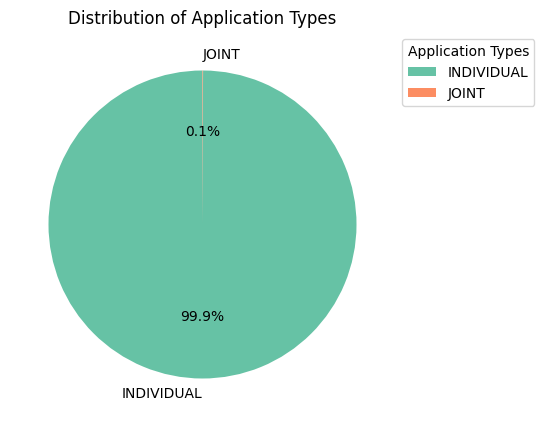

In [18]:
# Get the value counts for 'application_type'
application_type_counts = df['application_type'].value_counts()

# Set up the figure
plt.figure(figsize=(8, 5))

# Create the pie chart
plt.pie(application_type_counts.values, labels=application_type_counts.index, autopct='%1.1f%%', 
        startangle=90, colors=sns.color_palette('Set2'))

# Add a legend
plt.legend(application_type_counts.index, title="Application Types", bbox_to_anchor=(1, 1), loc="best")

# Set title
plt.title('Distribution of Application Types')

# Display the plot
plt.show()

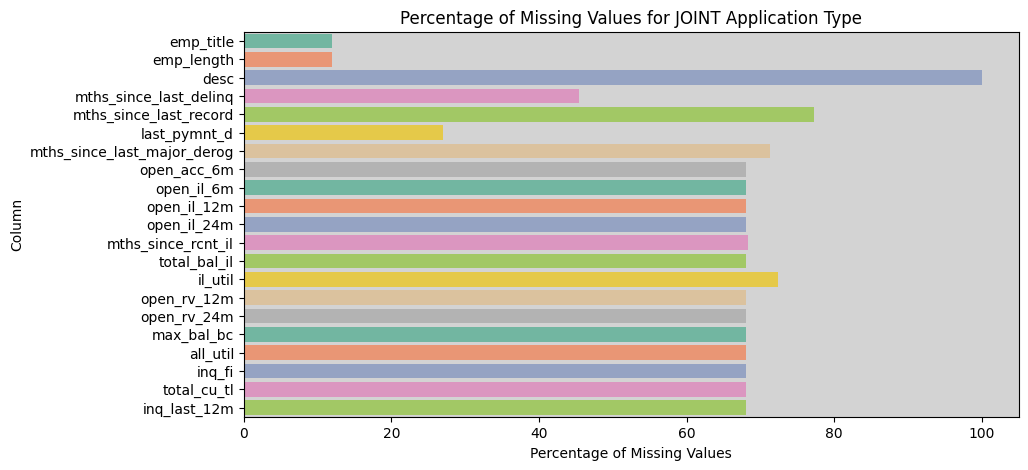

In [19]:
# Get the percentage of missing values for the 'JOINT' application type
joint_na_percentages = df[df['application_type'] == 'JOINT'].isna().mean() * 100

# Filter columns with more than 5% missing values
joint_na_percentages = joint_na_percentages[joint_na_percentages > 5]

# Set up the figure
plt.figure(figsize=(10, 5))

# Create the bar plot using Seaborn
sns.barplot(x=joint_na_percentages.values, y=joint_na_percentages.index, palette='Set2')

# Add labels and title
plt.xlabel('Percentage of Missing Values')
plt.ylabel('Column')
plt.title('Percentage of Missing Values for JOINT Application Type')

# Customize plot and background color
plt.gca().set_facecolor('lightgray')  # Background color inside the plot

# Show the plot
plt.show()

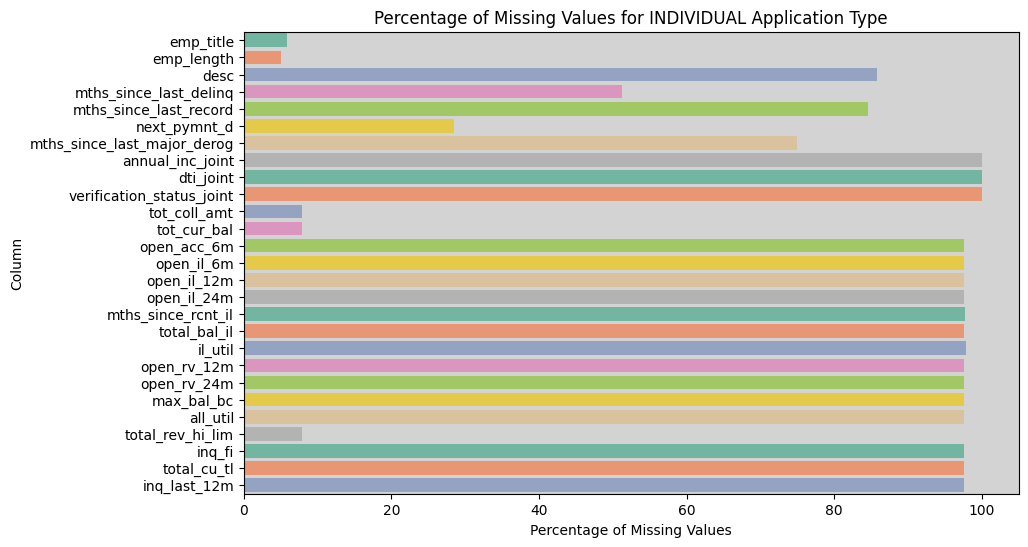

In [20]:
# Get the percentage of missing values for the 'INDIVIDUAL' application type
individual_na_percentages = df[df['application_type'] == 'INDIVIDUAL'].isna().mean() * 100

# Filter columns with more than 5% missing values
individual_na_percentages = individual_na_percentages[individual_na_percentages > 5]

# Set up the figure
plt.figure(figsize=(10, 6))

# Create the bar plot using Seaborn
sns.barplot(x=individual_na_percentages.values, y=individual_na_percentages.index, palette='Set2')

# Add labels and title
plt.xlabel('Percentage of Missing Values')
plt.ylabel('Column')
plt.title('Percentage of Missing Values for INDIVIDUAL Application Type')

# Customize plot and background color
plt.gca().set_facecolor('lightgray')  # Background color inside the plot

# Show the plot
plt.show()

drop JOINT records to keep all values for INDIVIDUAL application_type

In [22]:
df = df[df['application_type'] != 'JOINT']

In [23]:
df.shape

(886868, 74)

In [24]:
columns_to_drop = [i for i in df.columns if 'joint' in i]

columns_to_drop.append('application_type')

In [25]:
df.drop(columns=columns_to_drop, inplace=True)

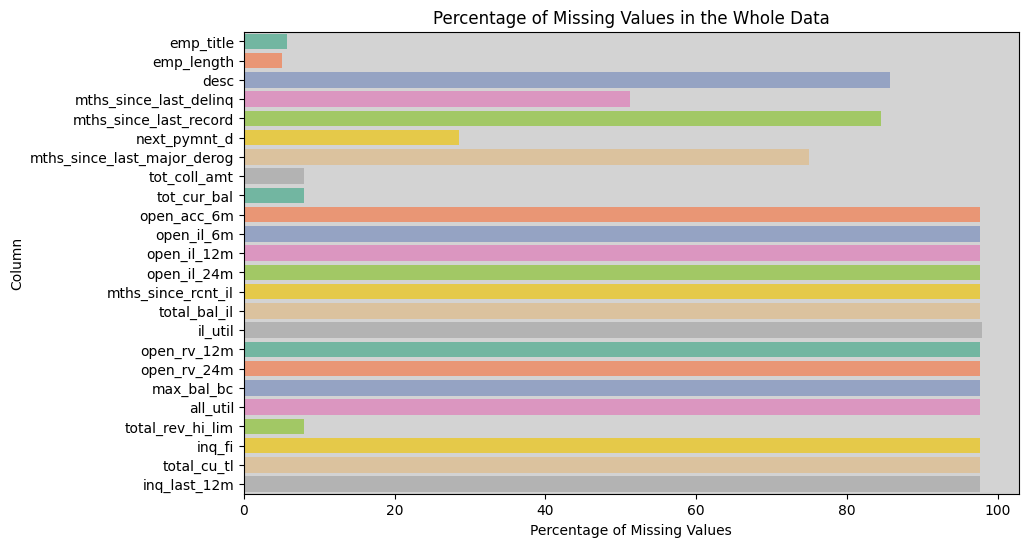

In [26]:
# Get the percentage of missing values for the entire DataFrame
na_percentages = df.isna().mean() * 100

# Filter columns with more than 5% missing values
na_percentages = na_percentages[na_percentages > 5]

# Set up the figure
plt.figure(figsize=(10, 6))

# Create the bar plot using Seaborn
sns.barplot(x=na_percentages.values, y=na_percentages.index, palette='Set2')

# Add labels and title
plt.xlabel('Percentage of Missing Values')
plt.ylabel('Column')
plt.title('Percentage of Missing Values in the Whole Data')

# Customize plot and background color
plt.gca().set_facecolor('lightgray')  # Background color inside the plot

# Show the plot
plt.show()

In [27]:
columns_to_drop = []

for i in df.columns:

  if df[i].isna().mean()*100 > 20:

    columns_to_drop.append(i)

In [28]:
df.drop(columns=columns_to_drop, inplace=True)

In [29]:
for i in df.columns:

  print({i: df[i].nunique()})

{'id': 886868}
{'member_id': 886868}
{'loan_amnt': 1372}
{'funded_amnt': 1372}
{'funded_amnt_inv': 9856}
{'term': 2}
{'int_rate': 542}
{'installment': 68701}
{'grade': 7}
{'sub_grade': 35}
{'emp_title': 299159}
{'emp_length': 11}
{'home_ownership': 6}
{'annual_inc': 49345}
{'verification_status': 3}
{'issue_d': 103}
{'loan_status': 10}
{'pymnt_plan': 2}
{'url': 886868}
{'purpose': 14}
{'title': 63143}
{'zip_code': 935}
{'addr_state': 51}
{'dti': 4000}
{'delinq_2yrs': 29}
{'earliest_cr_line': 696}
{'inq_last_6mths': 28}
{'open_acc': 77}
{'pub_rec': 32}
{'revol_bal': 73738}
{'revol_util': 1356}
{'total_acc': 135}
{'initial_list_status': 2}
{'out_prncp': 248246}
{'out_prncp_inv': 266137}
{'total_pymnt': 506637}
{'total_pymnt_inv': 506515}
{'total_rec_prncp': 260185}
{'total_rec_int': 324623}
{'total_rec_late_fee': 6181}
{'recoveries': 23055}
{'collection_recovery_fee': 20708}
{'last_pymnt_d': 98}
{'last_pymnt_amnt': 232437}
{'last_credit_pull_d': 103}
{'collections_12_mths_ex_med': 12}
{'

In [30]:
for i in df.columns:

    if df[i].nunique() < 10:

        print({i: df[i].value_counts()})

{'term': term
36 months    620886
60 months    265982
Name: count, dtype: int64}
{'grade': grade
B    254433
C    245717
A    148184
D    139419
E     70614
F     23022
G      5479
Name: count, dtype: int64}
{'home_ownership': home_ownership
MORTGAGE    443203
RENT        355995
OWN          87435
OTHER          182
NONE            50
ANY              3
Name: count, dtype: int64}
{'verification_status': verification_status
Source Verified    329424
Verified           290810
Not Verified       266634
Name: count, dtype: int64}
{'pymnt_plan': pymnt_plan
n    886858
y        10
Name: count, dtype: int64}
{'initial_list_status': initial_list_status
f    456703
w    430165
Name: count, dtype: int64}
{'policy_code': policy_code
1.0    886868
Name: count, dtype: int64}
{'acc_now_delinq': acc_now_delinq
0.0     882726
1.0       3865
2.0        208
3.0         28
4.0          7
5.0          3
6.0          1
14.0         1
Name: count, dtype: int64}


dropping 'pymnt_plan', 'policy_code', 'acc_now_delinq' cause they have same values for all people or rows in them (even though acc_now_delinq has a value of 1 for one row its still negligible while comparing it with 886k other rows)

In [31]:
df.drop(columns=['pymnt_plan', 'policy_code', 'acc_now_delinq'], inplace=True)

In [32]:
df[['grade', 'sub_grade']].head(5)

,grade,sub_grade
0,B,B2
1,C,C4
2,C,C5
3,C,C1
4,B,B5


since sub_grade is just more detailed version of grade with simply drop the grade coloumn along with 'id', 'member_id', 'url', 'issue_d', 'earliest_cr_line', 'last_credit_pull_d'

In [35]:
# Extract unique values and sort them cleanly
sub_grades = sorted(df['sub_grade'].dropna().unique())

print(sub_grades)

['A1', 'A2', 'A3', 'A4', 'A5', 'B1', 'B2', 'B3', 'B4', 'B5', 'C1', 'C2', 'C3', 'C4', 'C5', 'D1', 'D2', 'D3', 'D4', 'D5', 'E1', 'E2', 'E3', 'E4', 'E5', 'F1', 'F2', 'F3', 'F4', 'F5', 'G1', 'G2', 'G3', 'G4', 'G5']


In [36]:
df.drop(columns=['id', 'member_id', 'url', 'issue_d', 'earliest_cr_line', 'grade', 'last_credit_pull_d'], inplace=True)

we drop 'emp_title', 'title' as they have a lot of categories and would better suit a nlp model. 'zip_code', 'addr_state', 'last_pymnt_d' are dropped to generalize the data more than just to time period or place

In [37]:
df.drop(columns=['emp_title', 'title', 'zip_code', 'addr_state', 'last_pymnt_d'], inplace=True)

In [38]:
df.shape

(886868, 36)

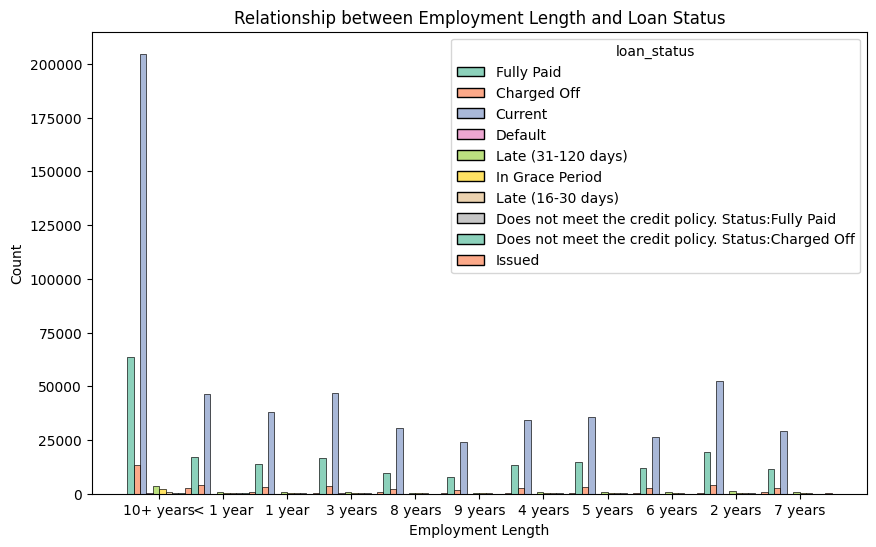

In [39]:
# Set up the figure
plt.figure(figsize=(10, 6))

# Create the histogram using Seaborn
sns.histplot(data=df, x="emp_length", hue="loan_status", multiple="dodge", palette='Set2')

# Add title and axis labels
plt.title("Relationship between Employment Length and Loan Status")
plt.xlabel("Employment Length")
plt.ylabel("Count")

# Show the plot
plt.show()

In [40]:
df.drop(columns=['emp_length'], inplace=True)

In [41]:
importante_features = df.columns

In [42]:
len(importante_features)

35

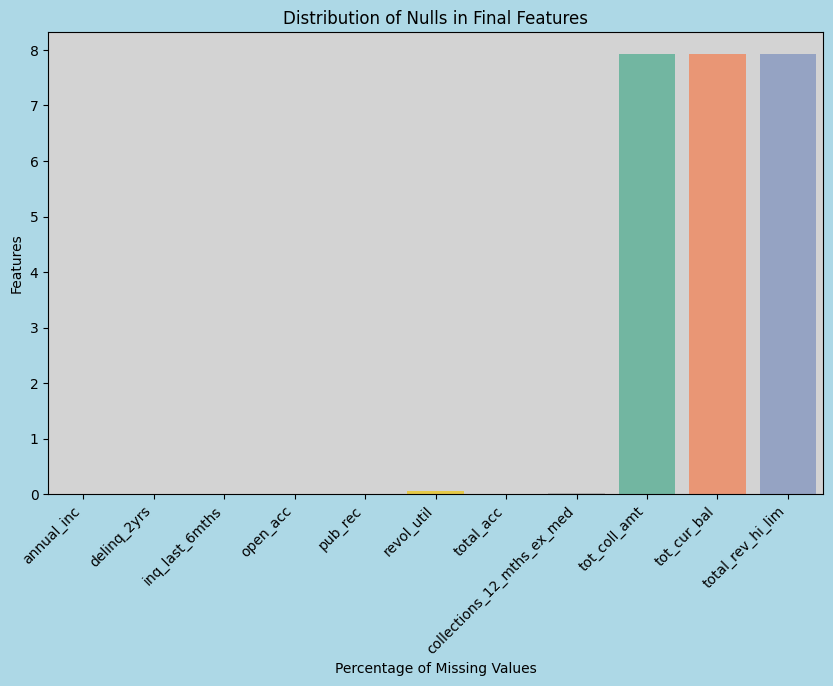

In [43]:
# Get the percentage of missing values for the entire DataFrame
na_percentages = df.isna().mean() * 100

# Filter columns with any missing values
na_percentages = na_percentages[na_percentages > 0]

# Set up the figure
plt.figure(figsize=(10, 6))

# Create the bar plot using Seaborn
sns.barplot(y=na_percentages.values, x=na_percentages.index, palette='Set2')

# Add labels and title
plt.xlabel('Percentage of Missing Values')
plt.ylabel('Features')
plt.title('Distribution of Nulls in Final Features')

# Rotate x-axis labels
plt.xticks(rotation=45, ha='right')  # Rotate labels and align them to the right

# Customize background color
plt.gca().set_facecolor('lightgray')  # Background color inside the plot
plt.gcf().set_facecolor('lightblue')  # Figure background color

# Display the plot
plt.show()

In [44]:
df[na_percentages.index].info()

<class 'pandas.DataFrame'>
Index: 886868 entries, 0 to 887378
Data columns (total 11 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   annual_inc                  886864 non-null  float64
 1   delinq_2yrs                 886839 non-null  float64
 2   inq_last_6mths              886839 non-null  float64
 3   open_acc                    886839 non-null  float64
 4   pub_rec                     886839 non-null  float64
 5   revol_util                  886366 non-null  float64
 6   total_acc                   886839 non-null  float64
 7   collections_12_mths_ex_med  886723 non-null  float64
 8   tot_coll_amt                816592 non-null  float64
 9   tot_cur_bal                 816592 non-null  float64
 10  total_rev_hi_lim            816592 non-null  float64
dtypes: float64(11)
memory usage: 81.2 MB


In [45]:
na_percentages

annual_inc                    0.000451
delinq_2yrs                   0.003270
inq_last_6mths                0.003270
open_acc                      0.003270
pub_rec                       0.003270
revol_util                    0.056604
total_acc                     0.003270
collections_12_mths_ex_med    0.016350
tot_coll_amt                  7.924065
tot_cur_bal                   7.924065
total_rev_hi_lim              7.924065
dtype: float64

In [46]:
print(df.shape)

for i in na_percentages.index:

  if na_percentages[i] < 1:

    df.dropna(subset=[i], inplace=True)

print(df.shape)

(886868, 35)
(886253, 35)


# Visualization for all important features

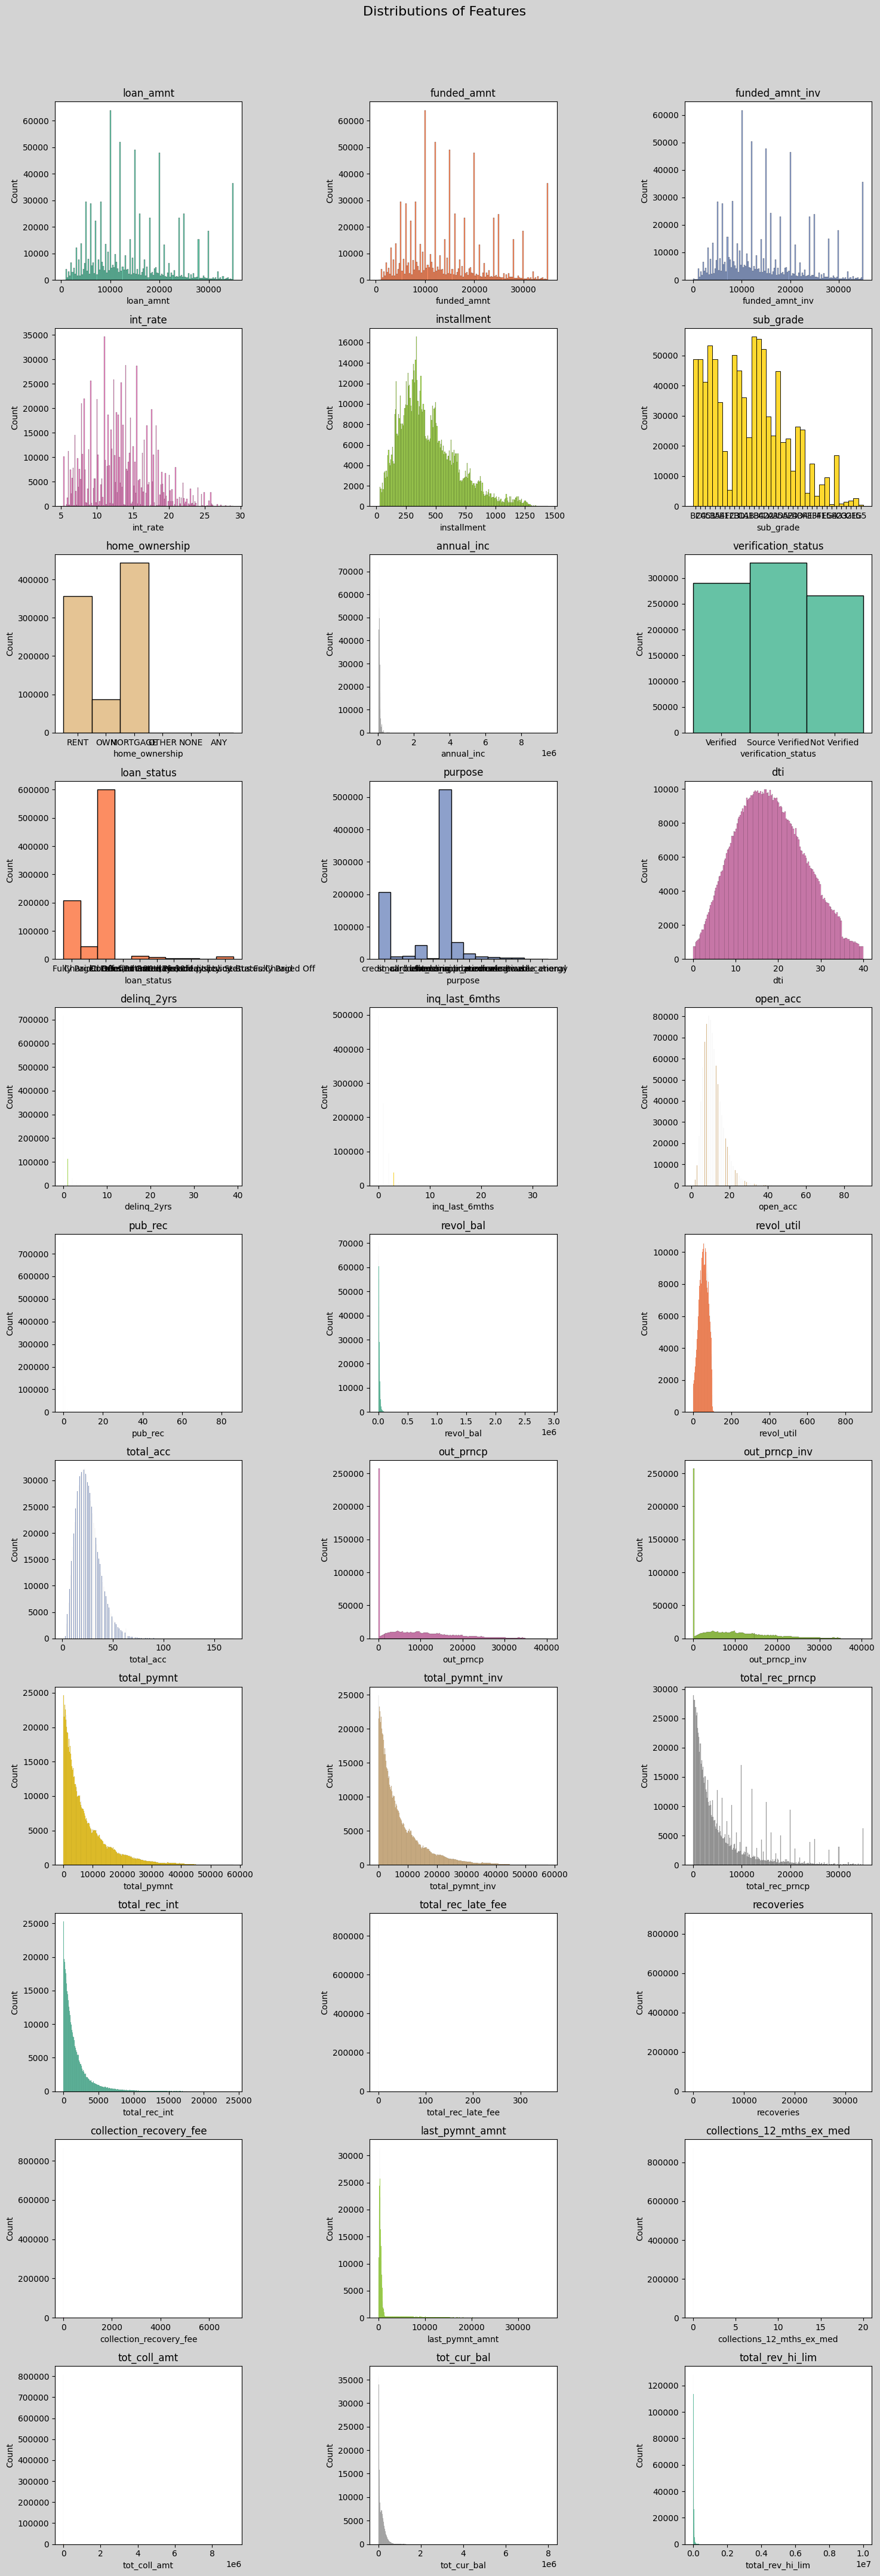

In [47]:
features = [col for col in df.columns if df[col].nunique() > 2]



rows = (len(features) + 2) // 3

cols = 3



# Set up the figure and axis for subplots

fig, axes = plt.subplots(rows, cols, figsize=(cols * 5, rows * 4))

axes = axes.flatten()  # Flatten in case of multiple rows



fig.patch.set_facecolor('lightgray')  # Set the background color of the entire figure



palette = sns.color_palette('Set2', len(features))



plotted_df = df.copy()

plotted_df['diff_loan_funded'] = plotted_df['loan_amnt'] - plotted_df['funded_amnt']

for i, col in enumerate(features):

    sns.histplot(x=plotted_df[col], kde=False, ax=axes[i], color=palette[i], alpha=1)  # Set alpha slightly transparent for better visualization

    axes[i].set_title(col)



# Remove any empty subplots (in case the number of features doesn't fill the grid)

for j in range(i + 1, len(axes)):

    fig.delaxes(axes[j])



fig.suptitle("Distributions of Features", fontsize=16)

plt.tight_layout(rect=[0, 0, 1, 0.96])  # Leave space for the main title



plt.show()

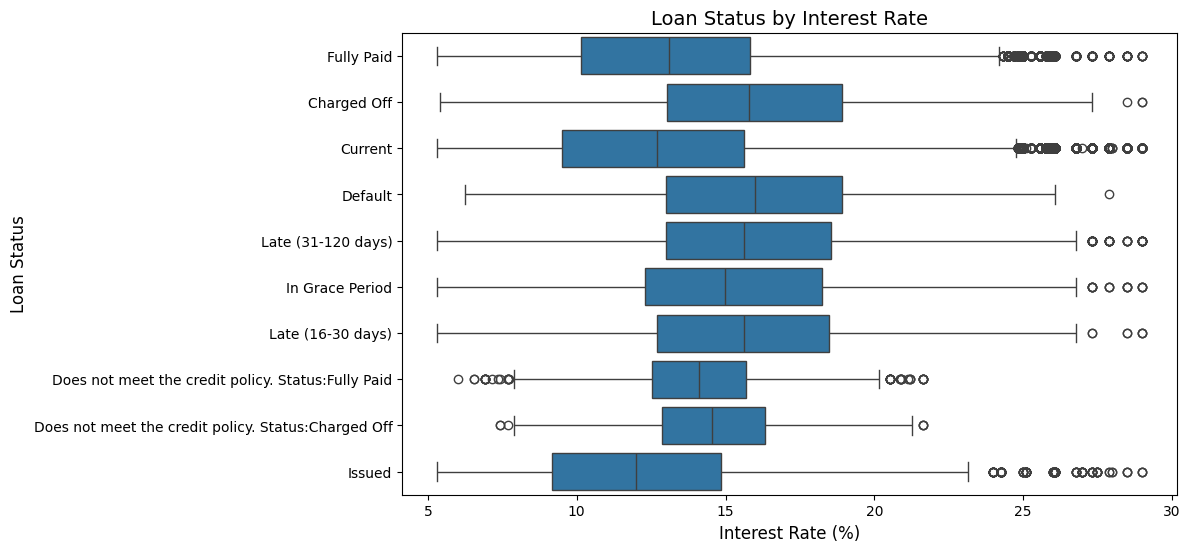

In [48]:
plt.figure(figsize=(10, 6))

sns.boxplot(x='int_rate', y='loan_status', data=df)



plt.title('Loan Status by Interest Rate', fontsize=14)

plt.xlabel('Interest Rate (%)', fontsize=12)

plt.ylabel('Loan Status', fontsize=12)



plt.show()

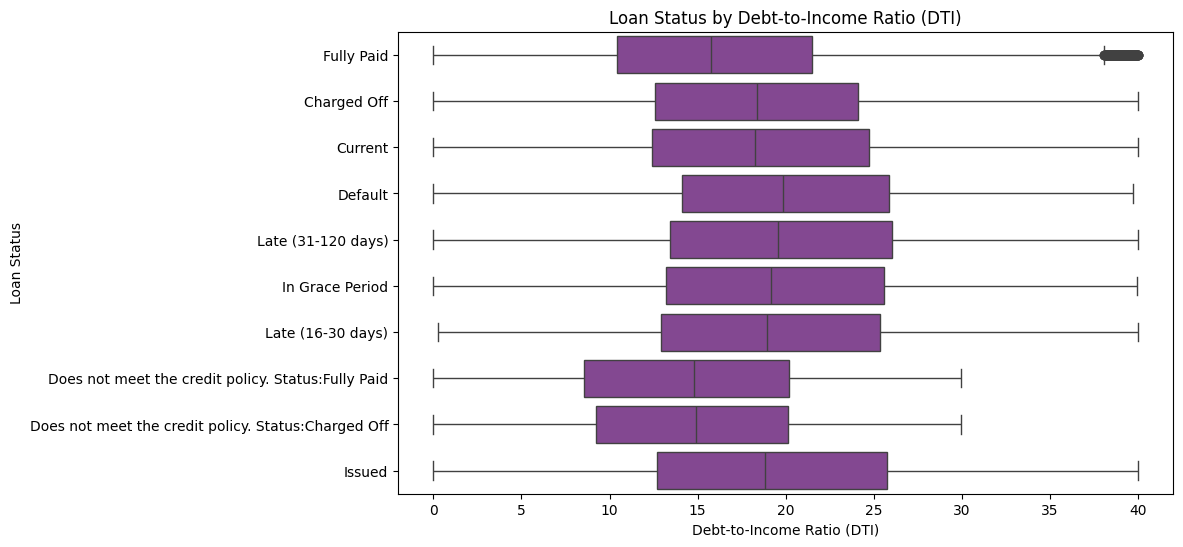

In [49]:
plt.figure(figsize=(10, 6))



sns.boxplot(x='dti', y='loan_status', data=df, color='#8A3C9D')



plt.title('Loan Status by Debt-to-Income Ratio (DTI)')

plt.xlabel('Debt-to-Income Ratio (DTI)')

plt.ylabel('Loan Status')



plt.show()

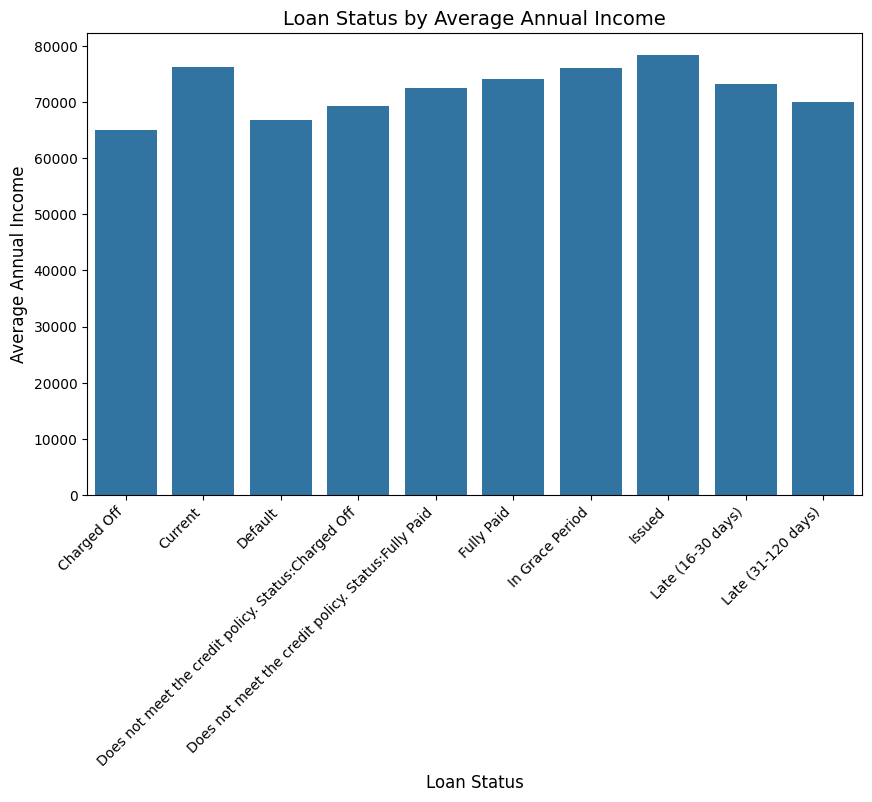

In [50]:
avg_income = df.groupby('loan_status')['annual_inc'].mean().reset_index()



plt.figure(figsize=(10, 6))

sns.barplot(y='annual_inc',x='loan_status', data=avg_income)



plt.title('Loan Status by Average Annual Income', fontsize=14)

plt.xlabel('Loan Status', fontsize=12)

plt.ylabel('Average Annual Income', fontsize=12)

plt.xticks(rotation=45, ha='right')



plt.show()

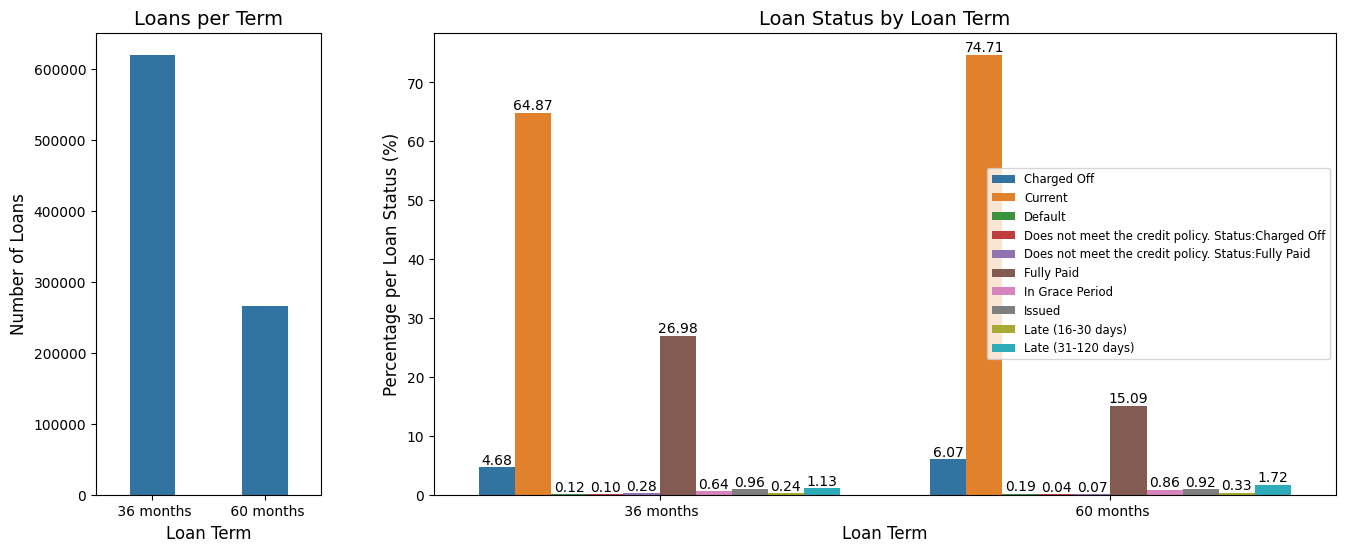

In [51]:
loans_per_term = df['term'].value_counts().reset_index()



count_data = df.groupby(['term', 'loan_status']).size().reset_index(name='count')

count_data['percentage'] = count_data['count'] / count_data.groupby('term')['count'].transform('sum') * 100



fig = plt.figure(figsize=(16, 6))

gs = gridspec.GridSpec(1, 2, width_ratios=[1, 4])



ax1 = plt.subplot(gs[0])

sns.barplot(x='term', y='count', data=loans_per_term, ax=ax1, width=0.4)

ax1.set_title('Loans per Term', fontsize=14)

ax1.set_xlabel('Loan Term', fontsize=12)

ax1.set_ylabel('Number of Loans', fontsize=12)



ax2 = plt.subplot(gs[1])

sns.barplot(x='term', y='percentage', hue='loan_status', data=count_data, ax=ax2, width=0.8)

for p in ax2.patches:

    height = p.get_height()

    if height > 0:

        ax2.text(

            p.get_x() + p.get_width() / 2.,

            height,

            f'{height:.2f}',

            ha='center',

            va='bottom'

        )

ax2.set_title('Loan Status by Loan Term', fontsize=14)

ax2.set_xlabel('Loan Term', fontsize=12)

ax2.set_ylabel('Percentage per Loan Status (%)', fontsize=12)



ax2.legend( fontsize='small')



plt.show()

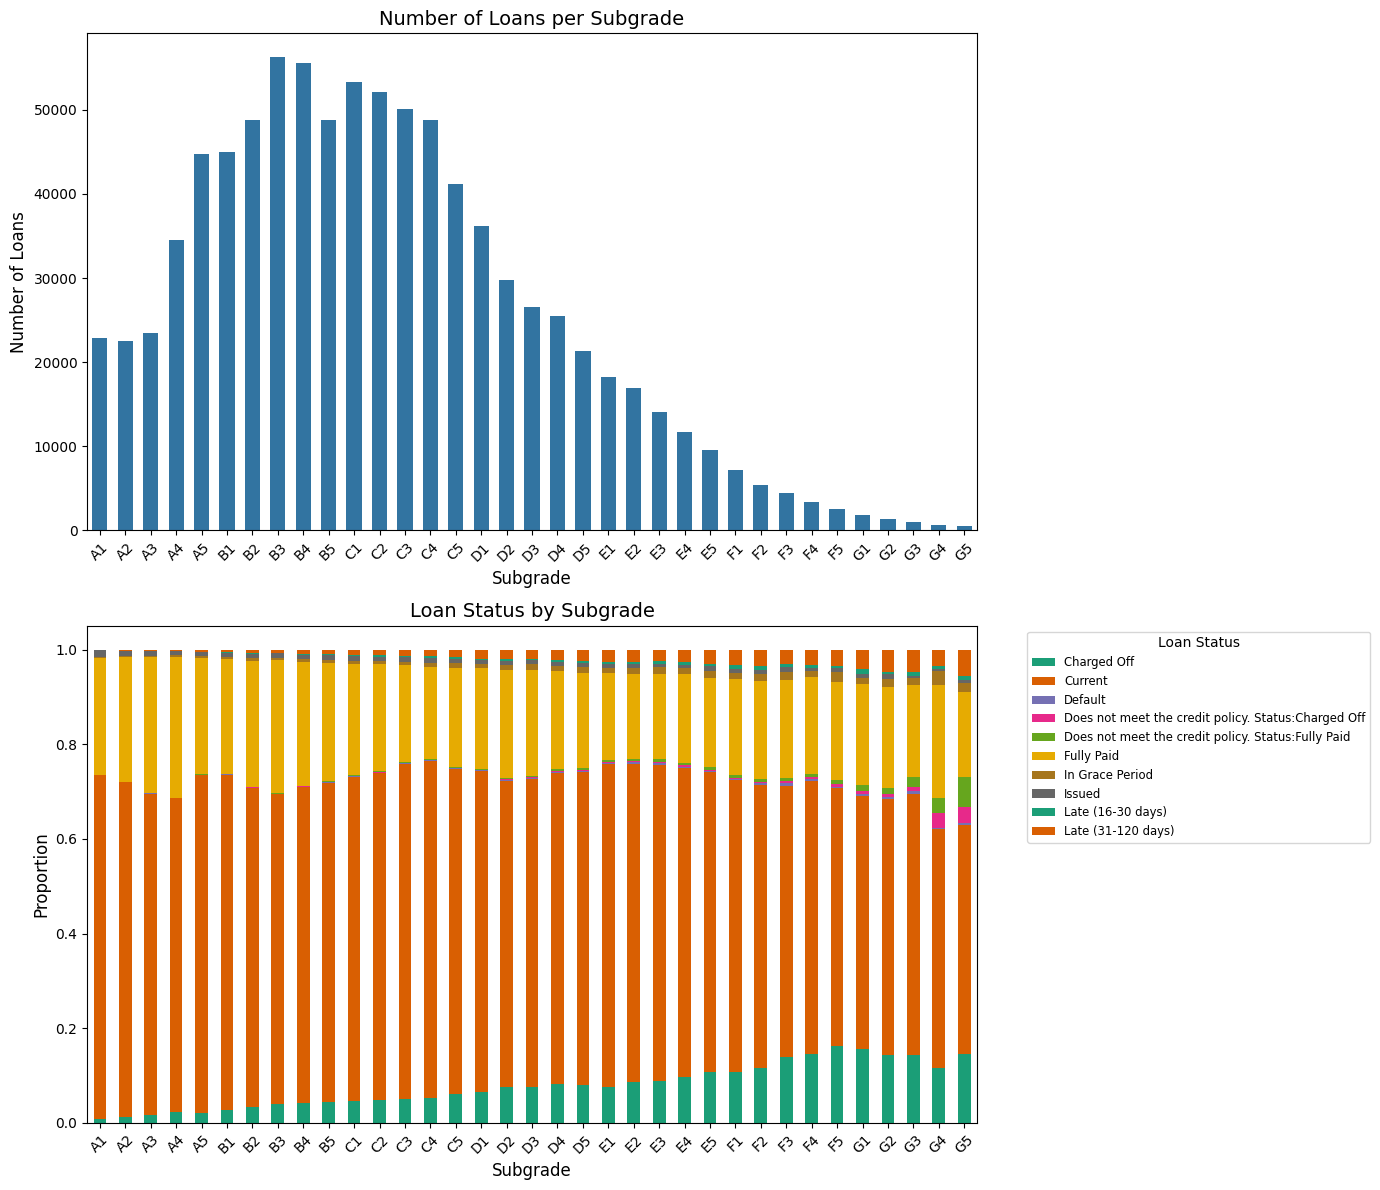

In [52]:
subgrade_counts = df['sub_grade'].value_counts().sort_index()



subgrade_proportions = df.groupby(['sub_grade', 'loan_status']).size().unstack(fill_value=0)

subgrade_proportions = subgrade_proportions.div(subgrade_proportions.sum(axis=1), axis=0)



fig, axes = plt.subplots(2, 1, figsize=(14, 12))

ax1, ax2 = axes[0], axes[1]



sns.barplot(x=subgrade_counts.index, y=subgrade_counts.values, ax=ax1, width=0.6)

ax1.set_title('Number of Loans per Subgrade', fontsize=14)

ax1.set_xlabel('Subgrade', fontsize=12)

ax1.set_ylabel('Number of Loans', fontsize=12)

ax1.tick_params(axis='x', rotation=45)



subgrade_proportions.plot(kind='bar', stacked=True, ax=ax2, color=sns.color_palette('Dark2'))

ax2.set_title('Loan Status by Subgrade', fontsize=14)

ax2.set_xlabel('Subgrade', fontsize=12)

ax2.set_ylabel('Proportion', fontsize=12)

ax2.tick_params(axis='x', rotation=45)

ax2.legend(title='Loan Status', bbox_to_anchor=(1.05, 1), loc='upper left', fontsize='small')



plt.tight_layout()

plt.show()

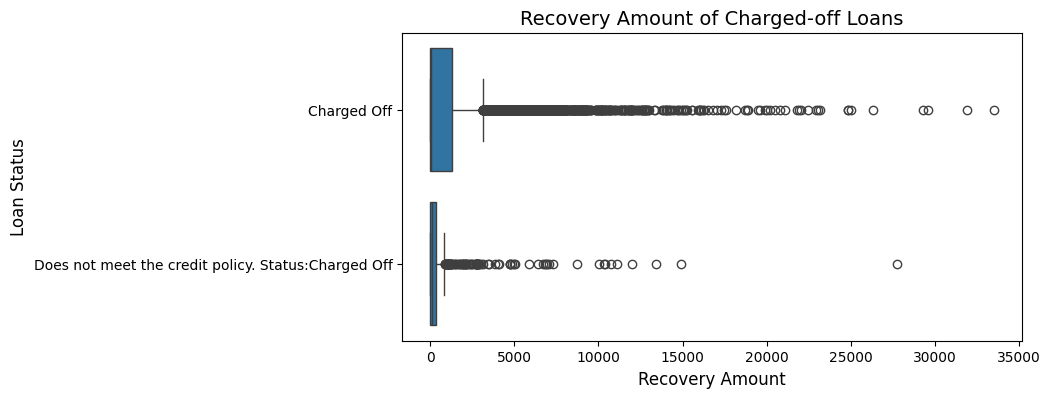

In [53]:
charges_off_df = df[df['loan_status'].str.contains('Charged Off')]



plt.figure(figsize=(8, 4))

sns.boxplot(x='recoveries', y='loan_status', data=charges_off_df)



plt.title('Recovery Amount of Charged-off Loans', fontsize=14)

plt.ylabel('Loan Status', fontsize=12)

plt.xlabel('Recovery Amount', fontsize=12)



plt.show()

<Figure size 800x1000 with 0 Axes>

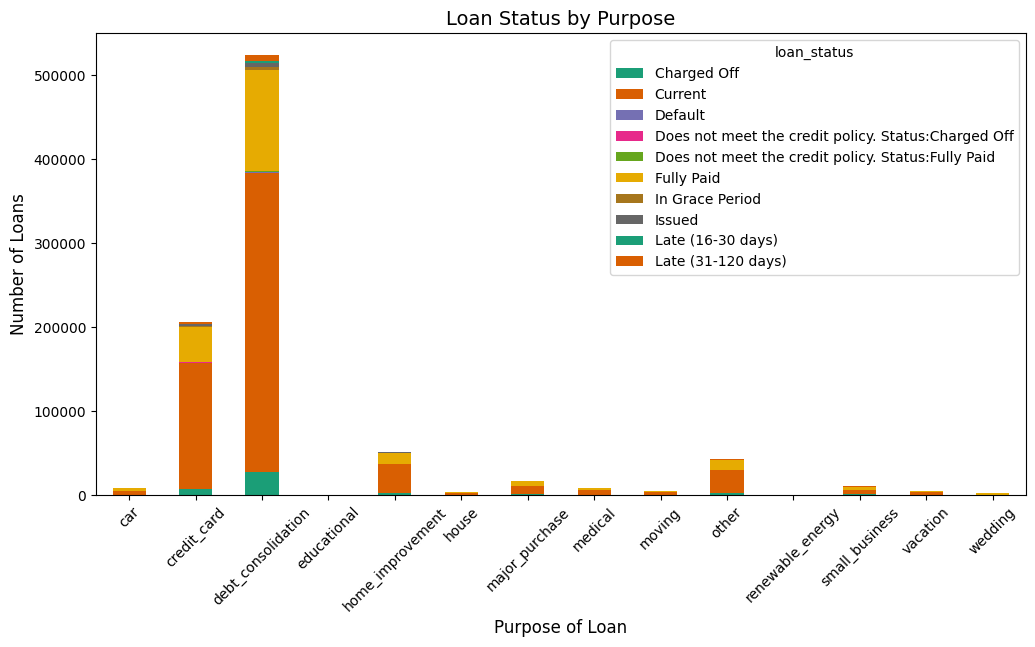

In [54]:
purpose_status_counts = df.groupby(['purpose', 'loan_status']).size().unstack(fill_value=0)



plt.figure(figsize=(8, 10))

purpose_status_counts.plot(kind='bar', stacked=True, figsize=(12, 6), color=sns.color_palette('Dark2'))



plt.title('Loan Status by Purpose', fontsize=14)

plt.xlabel('Purpose of Loan', fontsize=12)

plt.ylabel('Number of Loans', fontsize=12)

plt.xticks(rotation=45)



plt.show()


# Encoding

In [55]:
categorical_features = df.select_dtypes(include='object').drop(columns=['loan_status'])

In [56]:
categorical_features.head()

,term,sub_grade,home_ownership,verification_status,purpose,initial_list_status
0,36 months,B2,RENT,Verified,credit_card,f
1,60 months,C4,RENT,Source Verified,car,f
2,36 months,C5,RENT,Not Verified,small_business,f
3,36 months,C1,RENT,Source Verified,other,f
4,60 months,B5,RENT,Source Verified,other,f


In [57]:
for i in categorical_features.columns:

  print({i: categorical_features[i].value_counts()})

{'term': term
36 months    620387
60 months    265866
Name: count, dtype: int64}
{'sub_grade': sub_grade
B3    56283
B4    55568
C1    53329
C2    52179
C3    50097
C4    48785
B5    48774
B2    48748
B1    44951
A5    44791
C5    41168
D1    36164
A4    34511
D2    29754
D3    26507
D4    25506
A3    23444
A1    22907
A2    22467
D5    21345
E1    18234
E2    16960
E3    14105
E4    11687
E5     9542
F1     7203
F2     5374
F3     4422
F4     3399
F5     2589
G1     1864
G2     1388
G3      978
G4      659
G5      571
Name: count, dtype: int64}
{'home_ownership': home_ownership
MORTGAGE    442916
RENT        355748
OWN          87362
OTHER          180
NONE            44
ANY              3
Name: count, dtype: int64}
{'verification_status': verification_status
Source Verified    329259
Verified           290635
Not Verified       266359
Name: count, dtype: int64}
{'purpose': purpose
debt_consolidation    523642
credit_card           205989
home_improvement       51724
other            

In [58]:
def sub_grades_encoding(x):

  val = 0

  if 'A' in x:

    val = 7

  elif 'B' in x:

    val = 6

  elif 'C' in x:

    val = 5

  elif 'D' in x:

    val = 4

  elif 'E' in x:

    val = 3

  elif 'F' in x:

    val = 2

  elif 'G' in x:

    val = 1



  if '1' in x:

    val += 0.8

  elif '2' in x:

    val += 0.6

  elif '3' in x:

    val += 0.4

  elif '4' in x:

    val += 0.2

  elif '5' in x:

    val += 0.0



  return val



def verification_status(x):

  if x == 'Not Verified':

    return 0

  return 1

In [59]:
df['sub_grade'] = df['sub_grade'].apply(sub_grades_encoding)

In [60]:
df['sub_grade'].unique()

array([6.6, 5.2, 5. , 5.8, 6. , 7.2, 3.8, 2.6, 5.4, 6.8, 4.8, 7.8, 6.4,
       6.2, 5.6, 4.6, 7.4, 7. , 4. , 7.6, 3.2, 4.4, 4.2, 2.4, 3.4, 2.2,
       2.8, 3. , 1.2, 3.6, 1.4, 1.6, 1.8, 2. , 1. ])

In [61]:
from sklearn.preprocessing import LabelEncoder



label_encoder = LabelEncoder()



df['term'] = label_encoder.fit_transform(df['term'])

df['initial_list_status'] = label_encoder.fit_transform(df['initial_list_status'])

In [62]:
df['verification_status'] = df['verification_status'].apply(verification_status)

In [63]:
categorical_features = df.select_dtypes(include='object').drop(columns=['loan_status'])

In [64]:
categorical_features.isna().sum()

home_ownership    0
purpose           0
dtype: int64

In [65]:
encoded_features = pd.get_dummies(categorical_features, dtype=int)

encoded_features.head()

,home_ownership_ANY,home_ownership_MORTGAGE,home_ownership_NONE,home_ownership_OTHER,home_ownership_OWN,home_ownership_RENT,purpose_car,purpose_credit_card,purpose_debt_consolidation,purpose_educational,purpose_home_improvement,purpose_house,purpose_major_purchase,purpose_medical,purpose_moving,purpose_other,purpose_renewable_energy,purpose_small_business,purpose_vacation,purpose_wedding
0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0
3,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0
4,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0


In [66]:
df = pd.concat([df, encoded_features], axis=1)

In [67]:
df.drop(columns=categorical_features.columns, inplace=True)

In [68]:
df.head()

,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,sub_grade,annual_inc,verification_status,loan_status,dti,delinq_2yrs,inq_last_6mths,open_acc,pub_rec,revol_bal,revol_util,total_acc,initial_list_status,out_prncp,out_prncp_inv,total_pymnt,total_pymnt_inv,total_rec_prncp,total_rec_int,total_rec_late_fee,recoveries,collection_recovery_fee,last_pymnt_amnt,collections_12_mths_ex_med,tot_coll_amt,tot_cur_bal,total_rev_hi_lim,home_ownership_ANY,home_ownership_MORTGAGE,home_ownership_NONE,home_ownership_OTHER,home_ownership_OWN,home_ownership_RENT,purpose_car,purpose_credit_card,purpose_debt_consolidation,purpose_educational,purpose_home_improvement,purpose_house,purpose_major_purchase,purpose_medical,purpose_moving,purpose_other,purpose_renewable_energy,purpose_small_business,purpose_vacation,purpose_wedding
0,5000.0,5000.0,4975.0,0,10.65,162.87,6.6,24000.0,1,Fully Paid,27.65,0.0,1.0,3.0,0.0,13648.0,83.7,9.0,0,0.0,0.0,5861.071414,5831.78,5000.00,861.07,0.00,0.00,0.00,171.62,0.0,NaN,NaN,NaN,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0
1,2500.0,2500.0,2500.0,1,15.27,59.83,5.2,30000.0,1,Charged Off,1.00,0.0,5.0,3.0,0.0,1687.0,9.4,4.0,0,0.0,0.0,1008.710000,1008.71,456.46,435.17,0.00,117.08,1.11,119.66,0.0,NaN,NaN,NaN,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0
2,2400.0,2400.0,2400.0,0,15.96,84.33,5.0,12252.0,0,Fully Paid,8.72,0.0,2.0,2.0,0.0,2956.0,98.5,10.0,0,0.0,0.0,3003.653644,3003.65,2400.00,603.65,0.00,0.00,0.00,649.91,0.0,NaN,NaN,NaN,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0
3,10000.0,10000.0,10000.0,0,13.49,339.31,5.8,49200.0,1,Fully Paid,20.00,0.0,1.0,10.0,0.0,5598.0,21.0,37.0,0,0.0,0.0,12226.302212,12226.30,10000.00,2209.33,16.97,0.00,0.00,357.48,0.0,NaN,NaN,NaN,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0
4,3000.0,3000.0,3000.0,1,12.69,67.79,6.0,80000.0,1,Current,17.94,0.0,0.0,15.0,0.0,27783.0,53.9,38.0,0,766.9,766.9,3242.170000,3242.17,2233.10,1009.07,0.00,0.00,0.00,67.79,0.0,NaN,NaN,NaN,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0


In [69]:
df['loan_status'] = label_encoder.fit_transform(df['loan_status'])

In [70]:
df.isna().sum()

loan_amnt                         0
funded_amnt                       0
funded_amnt_inv                   0
term                              0
int_rate                          0
installment                       0
sub_grade                         0
annual_inc                        0
verification_status               0
loan_status                       0
dti                               0
delinq_2yrs                       0
inq_last_6mths                    0
open_acc                          0
pub_rec                           0
revol_bal                         0
revol_util                        0
total_acc                         0
initial_list_status               0
out_prncp                         0
out_prncp_inv                     0
total_pymnt                       0
total_pymnt_inv                   0
total_rec_prncp                   0
total_rec_int                     0
total_rec_late_fee                0
recoveries                        0
collection_recovery_fee     

In [ ]:
# Importing necessary libraries

from sklearn.experimental import enable_iterative_imputer  # To enable IterativeImputer

from sklearn.impute import IterativeImputer



# Initialize the IterativeImputer with optimized settings

imputer = IterativeImputer(max_iter=5, random_state=0)



# Fit and transform the data

imputed_data = imputer.fit_transform(df)



# Convert back to a DataFrame if needed

imputed_df = pd.DataFrame(imputed_data, columns=df.columns)

In [ ]:
imputed_df.to_csv('data/IterativeImputer_credit.csv', index=False)